# Kriging: ordinary, simple and cross-validation
Companion to [notes/spatial_statistics/kriging.md](../../notes/spatial_statistics/kriging.md). We solve the three-point system from the note, then build a small general kriging function and validate it.

In [1]:
import numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(7)

## 1. The three-point ordinary-kriging system
Semivariogram $\gamma(h)=0.2+2.8(1-e^{-h/1.5})$ for $h>0$ and $\gamma(0)=0$. Build $\Gamma$ and $\gamma_0$, add the sum-to-one row and column, and solve.

In [2]:
gam = lambda h: np.where(h > 0, 0.2 + 2.8*(1-np.exp(-h/1.5)), 0.0)
P = np.array([[0,0],[1,0],[0,1]], float); z3 = np.array([10,12,11.]); s0 = np.array([.5,.5])
G = gam(np.linalg.norm(P[:,None]-P[None], axis=2))
g0 = gam(np.linalg.norm(P-s0, axis=1))
A = np.zeros((4,4)); A[:3,:3] = G; A[:3,3] = 1; A[3,:3] = 1
sol = np.linalg.solve(A, np.r_[g0, 1])
lam, mu = sol[:3], sol[3]
print("Gamma =\n", G.round(4)); print("gamma0 =", g0.round(4))
print("weights", lam.round(4), "sum", lam.sum().round(6), "mu", mu.round(4))
print("prediction", (lam@z3).round(3), " variance", (lam@g0+mu).round(4))

Gamma =
 [[0.     1.5624 1.5624]
 [1.5624 0.     1.9093]
 [1.5624 1.9093 0.    ]]
gamma0 = [1.2524 1.2524 1.2524]
weights [0.2801 0.36   0.36  ] sum 1.0 mu 0.1276
prediction 11.08  variance 1.38


The weights sum to one (unbiasedness constraint), the prediction is $\approx11.08$ and the kriging variance $\lambda^\top\gamma_0+\mu\approx1.38$, matching the note. Although all three points are equidistant from the target, A gets a smaller weight than B and C: A is only 1 unit from each of B and C, whereas B and C are $\sqrt2$ apart, so A is more redundant with the other two and B and C are jointly more informative.

## 2. Simple kriging
Known mean $m=10$, $z=(12,9)$, covariance matrix and target covariances as in the note.

In [3]:
C = np.array([[4,1.5],[1.5,4]]); c0 = np.array([2.5,1.0]); m = 10; zz = np.array([12,9.])
lam = np.linalg.solve(C, c0)
print("weights", lam.round(3), "sum", lam.sum().round(3))
print("prediction", (m + lam@(zz-m)).round(3), " variance", (4 - c0@lam).round(3))

weights [0.618 0.018] sum 0.636
prediction 11.218  variance 2.436


## 3. A general ordinary-kriging function on a simulated field
We simulate a field on 60 random points and predict a grid. Both the prediction and the kriging standard deviation are mapped; the variance depends only on geometry and the model.

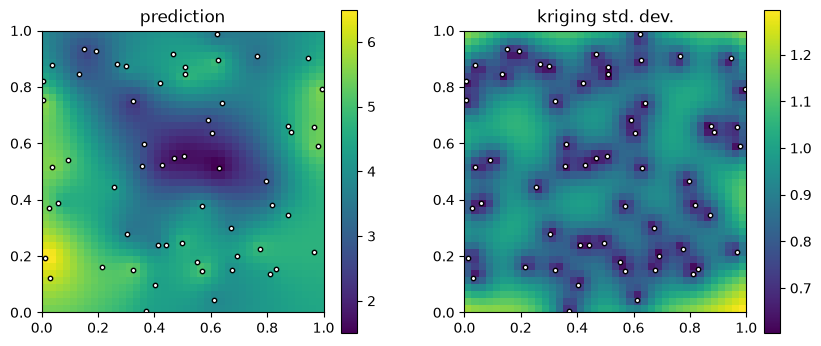

In [4]:
def ok_predict(xy, z, targets, gamma):
    n = len(z)
    G = gamma(np.linalg.norm(xy[:,None]-xy[None], axis=2))
    A = np.zeros((n+1,n+1)); A[:n,:n] = G; A[:n,n] = 1; A[n,:n] = 1
    G0 = gamma(np.linalg.norm(xy[:,None]-targets[None], axis=2))
    B = np.vstack([G0, np.ones(len(targets))])
    S = np.linalg.solve(A, B)
    pred = S[:n].T @ z
    var = (S[:n]*G0).sum(0) + S[n]
    return pred, var, S[:n]
c0_, c_, a_ = 0.2, 1.8, 0.25
cov = lambda h: c_*np.exp(-h/a_) + c0_*(h == 0)
n = 60
xy = rng.uniform(0, 1, (n, 2))
Cm = cov(np.linalg.norm(xy[:,None]-xy[None], axis=2))
z = 5 + np.linalg.cholesky(Cm) @ rng.standard_normal(n)
gamma = lambda h: np.where(h > 0, c0_ + c_*(1-np.exp(-h/a_)), 0.0)
gx = np.linspace(0, 1, 40); T = np.array([(x, y) for y in gx for x in gx])
pred, var, _ = ok_predict(xy, z, T, gamma)
fig, ax = plt.subplots(1, 2, figsize=(10,4.2))
for a, v, t in ((ax[0], pred, 'prediction'), (ax[1], np.sqrt(np.maximum(var, 0)), 'kriging std. dev.')):
    im = a.imshow(v.reshape(40,40), origin='lower', extent=[0,1,0,1]); a.scatter(xy[:,0], xy[:,1], c='w', s=10, edgecolor='k')
    a.set_title(t); plt.colorbar(im, ax=a)
plt.show()

## 4. Exactness at data points and weight signs
At a sampled location, with $\gamma(0)=0$, ordinary kriging returns the observation and zero variance. Weights may be negative.

In [5]:
p, v, W = ok_predict(xy, z, xy[:5], gamma)
print("max |pred - obs| at data:", np.abs(p - z[:5]).max().round(8), " max |variance|:", np.abs(v).max().round(8))
_, _, W = ok_predict(xy, z, T, gamma)
print("share of negative weights over the grid:", (W < 0).mean().round(3), " min weight:", W.min().round(3))

max |pred - obs| at data: 0.0  max |variance|: 0.0
share of negative weights over the grid: 0.38  min weight: -0.042


## 5. Leave-one-out cross-validation
Remove each point, predict it from the rest, and compute ME, RMSE and the standardized errors. A well-calibrated model has RMSSE near 1.

ME  = -0.008  RMSE = 0.834
mean std error = -0.003  RMSSE = 0.899


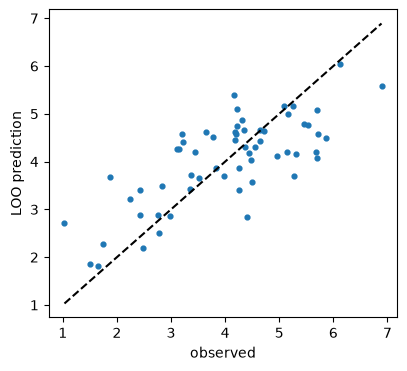

In [6]:
errs, stds = [], []
for k in range(n):
    keep = np.arange(n) != k
    p, v, _ = ok_predict(xy[keep], z[keep], xy[k:k+1], gamma)
    errs.append(z[k]-p[0]); stds.append(np.sqrt(max(v[0], 1e-12)))
errs, stds = np.array(errs), np.array(stds)
print("ME  =", errs.mean().round(3), " RMSE =", np.sqrt((errs**2).mean()).round(3))
print("mean std error =", (errs/stds).mean().round(3), " RMSSE =", np.sqrt(((errs/stds)**2).mean()).round(3))
plt.figure(figsize=(4.5,4)); plt.scatter(z, z-errs, s=12); lim=[z.min(), z.max()]
plt.plot(lim, lim, 'k--'); plt.xlabel('observed'); plt.ylabel('LOO prediction'); plt.show()

## 6. Variance does not depend on the data
Replacing the observed values by anything else leaves the weights and variance unchanged; only the prediction changes.

In [7]:
z2 = rng.normal(100, 20, n)
p1, v1, _ = ok_predict(xy, z, T[:3], gamma); p2, v2, _ = ok_predict(xy, z2, T[:3], gamma)
print("variances equal:", np.allclose(v1, v2), " predictions:", p1.round(2), p2.round(2))

variances equal: True  predictions: [5.47 5.46 5.43] [91.52 91.11 91.02]


## Takeaways
- Ordinary kriging solves $\Gamma\lambda+\mu\mathbf 1=\gamma_0$, $\mathbf 1^\top\lambda=1$; variance is $\lambda^\top\gamma_0+\mu$.
- Kriging variance depends on geometry and parameters, not on observed values.
- Leave-one-out diagnostics check bias (ME) and calibration (RMSSE), but remain optimistic for geographic extrapolation.